House Price Dataset

In [1]:
import pandas as pd
import numpy as np

df = pd.read_csv("../dataset/House Price Prediction.csv")

print("Dataset loaded successfully!")
print("Rows:", df.shape[0])
print("Columns:", df.shape[1])

Dataset loaded successfully!
Rows: 2000
Columns: 10


In [2]:
print("First 5 rows:")
display(df.head())

print("\nColumn names:")
print(df.columns.tolist())

print("\nDataset information:")
df.info()

First 5 rows:


,Id,Area,Bedrooms,Bathrooms,Floors,YearBuilt,Location,Condition,Garage,Price
0,1,1360,5,4,3,1970,Downtown,Excellent,No,149919
1,2,4272,5,4,3,1958,Downtown,Excellent,No,424998
2,3,3592,2,2,3,1938,Downtown,Good,No,266746
3,4,966,4,2,2,1902,Suburban,Fair,Yes,244020
4,5,4926,1,4,2,1975,Downtown,Fair,Yes,636056



Column names:
['Id', 'Area', 'Bedrooms', 'Bathrooms', 'Floors', 'YearBuilt', 'Location', 'Condition', 'Garage', 'Price']

Dataset information:
<class 'pandas.DataFrame'>
RangeIndex: 2000 entries, 0 to 1999
Data columns (total 10 columns):
 #   Column     Non-Null Count  Dtype
---  ------     --------------  -----
 0   Id         2000 non-null   int64
 1   Area       2000 non-null   int64
 2   Bedrooms   2000 non-null   int64
 3   Bathrooms  2000 non-null   int64
 4   Floors     2000 non-null   int64
 5   YearBuilt  2000 non-null   int64
 6   Location   2000 non-null   str  
 7   Condition  2000 non-null   str  
 8   Garage     2000 non-null   str  
 9   Price      2000 non-null   int64
dtypes: int64(7), str(3)
memory usage: 156.4 KB


In [3]:
print("Missing values in each column:")
print(df.isnull().sum())

print("\nTotal missing values:")
print(df.isnull().sum().sum())

Missing values in each column:
Id           0
Area         0
Bedrooms     0
Bathrooms    0
Floors       0
YearBuilt    0
Location     0
Condition    0
Garage       0
Price        0
dtype: int64

Total missing values:
0


In [4]:
duplicate_count = df.duplicated().sum()

print("Number of duplicate rows:", duplicate_count)

Number of duplicate rows: 0


In [5]:
print("Data types of each column:")
print(df.dtypes)

Data types of each column:
Id           int64
Area         int64
Bedrooms     int64
Bathrooms    int64
Floors       int64
YearBuilt    int64
Location       str
Condition      str
Garage         str
Price        int64
dtype: object


In [6]:
print("Price Statistics:")
print(df["Price"].describe())

print("\nMinimum Price:", df["Price"].min())
print("Maximum Price:", df["Price"].max())
print("Average Price:", round(df["Price"].mean(), 2))
print("Median Price:", df["Price"].median())

Price Statistics:
count      2000.000000
mean     537676.855000
std      276428.845719
min       50005.000000
25%      300098.000000
50%      539254.000000
75%      780086.000000
max      999656.000000
Name: Price, dtype: float64

Minimum Price: 50005
Maximum Price: 999656
Average Price: 537676.86
Median Price: 539254.0


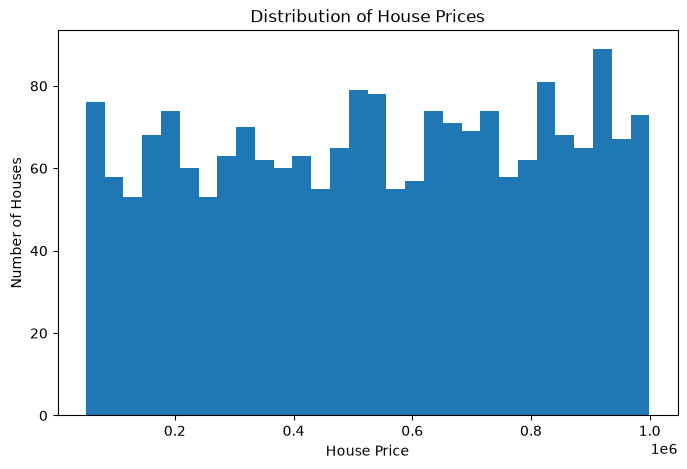

In [7]:
import matplotlib.pyplot as plt

plt.figure(figsize=(8, 5))

plt.hist(df["Price"], bins=30)

plt.title("Distribution of House Prices")
plt.xlabel("House Price")
plt.ylabel("Number of Houses")

plt.show()

In [8]:
# Select only numerical columns
numeric_df = df.select_dtypes(include=np.number)

print("Numerical columns:")
print(numeric_df.columns.tolist())

print("\nCorrelation with Price:")
print(
    numeric_df.corr()["Price"]
    .sort_values(ascending=False)
)

Numerical columns:
['Id', 'Area', 'Bedrooms', 'Bathrooms', 'Floors', 'YearBuilt', 'Price']

Correlation with Price:
Price        1.000000
Floors       0.055890
YearBuilt    0.004845
Area         0.001542
Bedrooms    -0.003471
Bathrooms   -0.015737
Id          -0.025643
Name: Price, dtype: float64


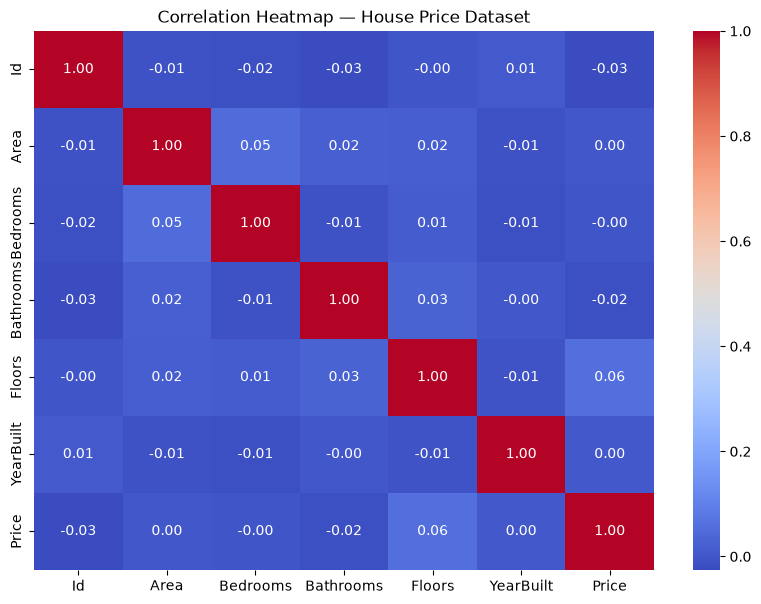

In [9]:
import seaborn as sns
import matplotlib.pyplot as plt

numeric_df = df.select_dtypes(include=np.number)

plt.figure(figsize=(10, 7))

sns.heatmap(
    numeric_df.corr(),
    annot=True,
    cmap="coolwarm",
    fmt=".2f"
)

plt.title("Correlation Heatmap — House Price Dataset")
plt.show()

In [10]:
# Target variable
y = df["Price"]

# Features
X = df.drop("Price", axis=1)

print("Features (X):")
print(X.columns.tolist())

print("\nTarget (y):")
print(y.name)

print("\nX shape:", X.shape)
print("y shape:", y.shape)

Features (X):
['Id', 'Area', 'Bedrooms', 'Bathrooms', 'Floors', 'YearBuilt', 'Location', 'Condition', 'Garage']

Target (y):
Price

X shape: (2000, 9)
y shape: (2000,)


In [11]:
print("Numerical Features:")
print(numerical_features)

print("\nCategorical Features:")
print(categorical_features)

Numerical Features:


NameError: name 'numerical_features' is not defined

In [ ]:
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder

preprocessor = ColumnTransformer(
    transformers=[
        ("num", "passthrough", numerical_features),
        ("cat", OneHotEncoder(handle_unknown="ignore"), categorical_features)
    ]
)

print("Preprocessing pipeline created successfully!")

Preprocessing pipeline created successfully!


In [ ]:
from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42
)

print("Training data:")
print("X_train:", X_train.shape)
print("y_train:", y_train.shape)

print("\nTesting data:")
print("X_test:", X_test.shape)
print("y_test:", y_test.shape)

Training data:
X_train: (1600, 9)
y_train: (1600,)

Testing data:
X_test: (400, 9)
y_test: (400,)


In [ ]:
from sklearn.pipeline import Pipeline
from sklearn.linear_model import LinearRegression

model = Pipeline(
    steps=[
        ("preprocessor", preprocessor),
        ("regressor", LinearRegression())
    ]
)

# Train the model
model.fit(X_train, y_train)

print("Linear Regression model trained successfully!")

Linear Regression model trained successfully!


In [ ]:
# Make predictions
y_pred = model.predict(X_test)

print("Predictions generated successfully!")
print("Number of predictions:", len(y_pred))

print("\nFirst 10 predicted prices:")
print(y_pred[:10])

Predictions generated successfully!
Number of predictions: 400

First 10 predicted prices:
[511317.73109931 557359.55652936 482838.34523391 540695.6411198
 549288.50244107 518144.16928401 523405.40235976 568346.51627797
 556990.3977267  573402.71846042]


In [ ]:
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
import numpy as np

mae = mean_absolute_error(y_test, y_pred)
mse = mean_squared_error(y_test, y_pred)
rmse = np.sqrt(mse)
r2 = r2_score(y_test, y_pred)

print("========== MODEL EVALUATION ==========")
print("Mean Absolute Error (MAE):", round(mae, 2))
print("Mean Squared Error (MSE):", round(mse, 2))
print("Root Mean Squared Error (RMSE):", round(rmse, 2))
print("R² Score:", round(r2, 4))

========== MODEL EVALUATION ==========
Mean Absolute Error (MAE): 242867.45
Mean Squared Error (MSE): 78279764120.86
Root Mean Squared Error (RMSE): 279785.21
R² Score: -0.0062


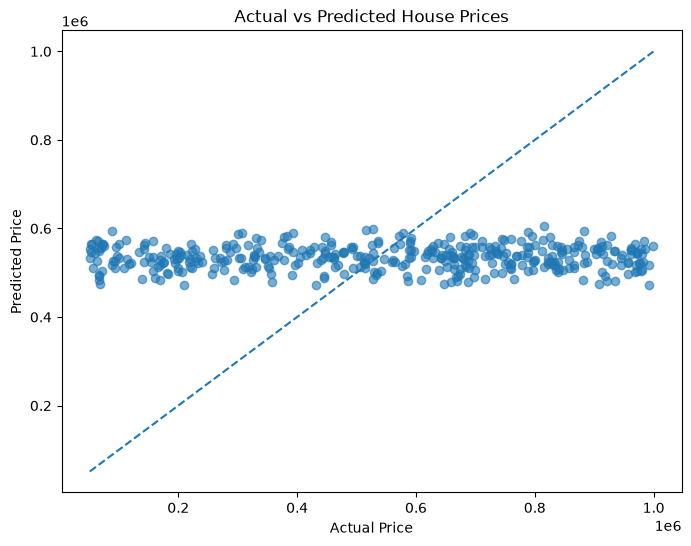

In [ ]:
plt.figure(figsize=(8, 6))

plt.scatter(y_test, y_pred, alpha=0.6)

# Perfect prediction reference line
min_price = min(y_test.min(), y_pred.min())
max_price = max(y_test.max(), y_pred.max())

plt.plot(
    [min_price, max_price],
    [min_price, max_price],
    linestyle="--"
)

plt.title("Actual vs Predicted House Prices")
plt.xlabel("Actual Price")
plt.ylabel("Predicted Price")

plt.show()

In [ ]:
comparison = pd.DataFrame({
    "Actual Price": y_test.values,
    "Predicted Price": y_pred
})

comparison["Difference"] = (
    comparison["Actual Price"] - comparison["Predicted Price"]
)

display(comparison.head(10))

,Actual Price,Predicted Price,Difference
0,514764,511317.731099,3446.268901
1,694256,557359.556529,136896.443471
2,66375,482838.345234,-416463.345234
3,650243,540695.641120,109547.358880
4,223285,549288.502441,-326003.502441
5,468127,518144.169284,-50017.169284
6,513002,523405.402360,-10403.402360
7,911525,568346.516278,343178.483722
8,723265,556990.397727,166274.602273
9,339416,573402.718460,-233986.718460


In [ ]:
# Calculate correlations with Price
price_correlations = (
    numeric_df.corr()["Price"]
    .drop("Price")
    .sort_values(ascending=False)
)

print("Correlation of Numerical Features with Price:")
print(price_correlations)

Correlation of Numerical Features with Price:
Floors       0.055890
YearBuilt    0.004845
Area         0.001542
Bedrooms    -0.003471
Bathrooms   -0.015737
Id          -0.025643
Name: Price, dtype: float64


In [ ]:
import os

output_file = "../output/house_price_predictions.csv"

comparison.to_csv(output_file, index=False)

print("Prediction results saved successfully!")
print("File:", output_file)
print("File exists:", os.path.exists(output_file))

Prediction results saved successfully!
File: ../output/house_price_predictions.csv
File exists: True


In [ ]:
print("========== HOUSE PRICE PREDICTION SUMMARY ==========")

print("Dataset Size:", df.shape)

print("Training Records:", len(X_train))
print("Testing Records:", len(X_test))

print("\nModel: Linear Regression")

print("\nModel Performance:")
print("MAE:", round(mae, 2))
print("MSE:", round(mse, 2))
print("RMSE:", round(rmse, 2))
print("R² Score:", round(r2, 4))

print("\nTarget Variable: Price")

print("\nNumerical Features:")
print(numerical_features)

print("\nCategorical Features:")
print(categorical_features)

========== HOUSE PRICE PREDICTION SUMMARY ==========
Dataset Size: (2000, 10)
Training Records: 1600
Testing Records: 400

Model: Linear Regression

Model Performance:
MAE: 242867.45
MSE: 78279764120.86
RMSE: 279785.21
R² Score: -0.0062

Target Variable: Price

Numerical Features:
['Id', 'Area', 'Bedrooms', 'Bathrooms', 'Floors', 'YearBuilt']

Categorical Features:
['Location', 'Condition', 'Garage']


# Final Observations and Conclusion

## Observations

1. The dataset contains 2,000 house records with 10 columns.
2. The target variable for prediction is `Price`.
3. Numerical and categorical features were separated during preprocessing.
4. Categorical features were converted into numerical form using One-Hot Encoding.
5. A Linear Regression model was trained using 80% of the dataset and evaluated using the remaining 20%.
6. Model performance was evaluated using MAE, MSE, RMSE, and R² Score.
7. The Actual vs Predicted Price visualization was used to compare model predictions with actual house prices.
8. The correlation analysis helped identify numerical factors associated with house prices.

## Conclusion

The Linear Regression model provides a baseline approach for predicting house prices from property characteristics. The preprocessing pipeline allows both numerical and categorical features to be used in the model. The evaluation metrics and Actual vs Predicted visualization provide a clear understanding of the model's prediction performance.

The model can be further improved in future work by testing additional regression algorithms, performing feature engineering, and tuning model parameters.